<a href="https://colab.research.google.com/github/sohyun223/ai-application-2026/blob/main/Week07_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 7주차 실습 — 왜 이탈하는가: 공변량 이동 진단 · DAgger 2회전 · 정책 v2
**AI Application · 스마트모빌리티학과 · 2026-10-14 · 파이프라인 ⑤ 평가 + ⑥ 반복**

| 셀 | 내용 |
|---|---|
| 0-1 | 이 머신의 속도 측정 → 예상 실행 시간, FAST 자동 설정 |
| 1 | 진단 — 학습 데이터의 (d, ψ) 분포 vs 정책 v1 이 실제로 방문하는 상태 (커버리지) |
| 2 | DAgger 한 회전 함수 + 평가 함수 (외란 1.0× / 1.2×) |
| 3 | DAgger 2회전 실행 — 회전별 기록 |
| 4 | 곡선·커버리지 — 무엇이 바뀌었나 |
| 5 | (선택) β 혼합 수집 — 데이터 분포가 어떻게 달라지나 |
| 6 | 짝지은 비교 — v1 vs v2, 같은 시드 3개 |
| 7 | 저장 — my_policy_v2.onnx · 집계 데이터 · 실험 기록 CSV |
| 8 | (집에서) 회전 3~5 이어서 |

**준비물**: `tinytrack.py`, `models/base_pilotnet.pt`(v1 정책이 없을 때만), Drive 의 `week06/my_policy_v1.pt` 와 `week05/my_dataset_v1.npz`. 없으면 즉석 생성. CPU 로 전체 6~8분.

**약어**: DAgger = Dataset Aggregation(정책이 운전 → 전문가가 라벨 → 집계 → 재학습, Ross 외 AISTATS 2011, arXiv:1011.0686) · BC = Behavior Cloning(행동 복제) · β 혼합 = 확률 β 로 전문가 조향을 섞어 운전 · MAE = 평균절대오차 · npz = numpy 압축 배열 · ONNX = 공통 모델 형식 · CSV = 쉼표 구분 표

In [1]:
# ============ 0. 준비 (재접속 시 여기부터) ============
import importlib.util, subprocess, sys, os, time, json
for pkg in ["onnx", "onnxruntime", "pandas"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
import numpy as np, matplotlib.pyplot as plt, pandas as pd, torch
from pathlib import Path
try:
    import tinytrack as tt
except ImportError:
    from google.colab import files
    print("tinytrack.py 를 업로드하세요"); files.upload(); import tinytrack as tt
try:
    from google.colab import drive
    drive.mount("/content/drive"); ROOT = Path("/content/drive/MyDrive/AIApp")
except Exception:
    ROOT = Path("./outputs")
SAVE_DIR = ROOT / "week07"; SAVE_DIR.mkdir(parents=True, exist_ok=True)
torch.manual_seed(0); np.random.seed(0)

# --- 데이터 v1 (과제 2) → 없으면 즉석 생성
v1_path = ROOT / "week05" / "my_dataset_v1.npz"
if v1_path.exists():
    D = tt.load_npz(v1_path); print("v1 로드:", len(D["steers"]), "프레임")
else:
    print("v1 이 없어 즉석 생성합니다 (약 20초)")
    D = tt.rebalance(tt.merge(*[tt.collect(tt.ExpertPolicy(), tt.Track.preset(n), 500, seed=10 * ord(n) + k, noise_inject=ni)
                                for n in "ABC" for k, ni in enumerate([0.0, 0.4, 0.8])]))
D = {k: D[k] for k in ("images", "steers", "states", "run_id")}
N0 = len(D["steers"])

# --- 정책 v1 (6주차 미세조정) → 없으면 베이스에서 3에폭 즉석 미세조정
v1_pt = ROOT / "week06" / "my_policy_v1.pt"
if v1_pt.exists():
    model = tt.load_model(v1_pt); print("v1 정책 로드")
else:
    MODELS = Path("models") if Path("models/base_pilotnet.pt").exists() else Path(".")
    if not (MODELS / "base_pilotnet.pt").exists():
        from google.colab import files
        print("base_pilotnet.pt 를 업로드하세요"); files.upload()
    print("v1 정책이 없어 베이스에서 3에폭 미세조정합니다 (약 1분)")
    model = tt.load_model(MODELS / "base_pilotnet.pt")
    tr0, va0 = tt.split_by_run(D, 0.2, seed=0)
    tt.train_bc(model, tr0, va0, epochs=3, lr=3e-4, augment=tt.make_augment(seed=0), verbose=False)
torch.save(model.state_dict(), SAVE_DIR / "policy_round0.pt")

PUBLIC, HIDDEN = ["A", "B", "C"], [tt.Track.random(101), tt.Track.random(202)]
NORMAL = tt.DEFAULT_DISTURB                                  # 외란 1.0×
HARD = dict(every=50, d=0.35 * 1.2, psi=0.3 * 1.2)           # 외란 1.2× (1.5× 는 어떤 정책도 완주 불가 — 쓰지 않음)
print("tinytrack", tt.__version__, "| 데이터", N0, "| 저장:", SAVE_DIR)

tinytrack.py 를 업로드하세요


Saving tinytrack.py to tinytrack.py
Mounted at /content/drive
v1 로드: 2848 프레임
v1 정책 로드
tinytrack 0.3.1 | 데이터 2848 | 저장: /content/drive/MyDrive/AIApp/week07


### 0-1. 이 머신의 속도 측정 (5초) → 예상 실행 시간과 `FAST` 자동 설정
느린 머신(Colab 무료 CPU 등)이면 `FAST=True` 가 되어 학습 프레임·에폭을 줄입니다. 결과의 방향은 같고 숫자만 조금 거칩니다. 직접 바꾸려면 아래 셀에서 `FAST = True/False` 로 덮어쓰세요.

In [2]:
import time as _t
_t0 = _t.time(); [tt.render(0.1, 0.05, 0.1) for _ in range(300)]; _tr = _t.time() - _t0
_m = tt.make_model().eval(); _x = torch.zeros(64, 3, tt.H, tt.W)
with torch.no_grad():
    _m(_x); _t0 = _t.time(); [_m(_x) for _ in range(10)]; _tf = _t.time() - _t0
REF_RENDER, REF_FWD, REF_MIN = 0.195, 0.318, 8          # 제작 PC 기준값 (렌더 300장 s, 순전파 10회 s, 전체 실행 분)
ratio = 0.5 * (_tr / REF_RENDER) + 0.5 * (_tf / REF_FWD)
FAST = os.environ.get("NB_FAST") == "1" or ratio > 1.8
print(f"렌더 300장 {_tr:.2f}s · 순전파 10회 {_tf:.2f}s → 제작 PC 대비 {ratio:.1f}배 → 예상 전체 실행 약 {REF_MIN * ratio * (0.6 if FAST else 1.0):.0f}분 | FAST = {FAST}")

렌더 300장 0.33s · 순전파 10회 1.48s → 제작 PC 대비 3.2배 → 예상 전체 실행 약 15분 | FAST = True


## 1. 진단 — 정책이 가는 곳에 데이터가 있는가
학습 데이터의 상태 `(d, ψ)` 분포(격자 히스토그램)와, 정책 v1 이 **외란 포함으로 실제 주행하며 방문한** 상태를 겹쳐 봅니다.
**커버리지** = 정책이 방문한 격자 칸 중 학습 데이터가 5개 이상 있는 칸의 비율. 낮을수록 '정책은 가는데 데이터는 없는' 곳이 많습니다.

정책 v1 방문 상태 4500개 | 커버리지 0.41 | 방문 |d| 최대 0.42


/tmp/ipykernel_3210/3633920107.py:32: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "coverage_round0.png", dpi=120); plt.show()
/tmp/ipykernel_3210/3633920107.py:32: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "coverage_round0.png", dpi=120); plt.show()
/tmp/ipykernel_3210/3633920107.py:32: UserWarning: Glyph 45936 (\N{HANGUL SYLLABLE DE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "coverage_round0.png", dpi=120); plt.show()
/tmp/ipykernel_3210/3633920107.py:32: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "coverage_round0.png", dpi=120); plt.show()
/tmp/ipykernel_3210/3633920107.py:32: UserWarning: Glyph 53552 (\N{HANGUL SYLLABLE TEO}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savef

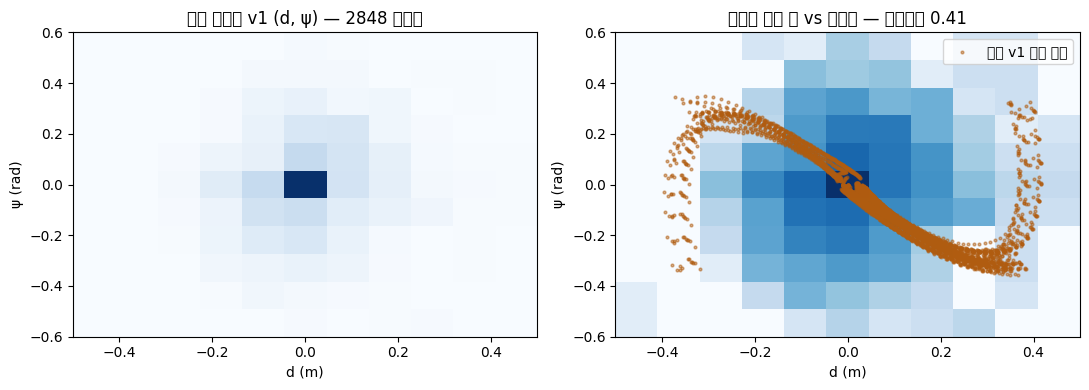

In [3]:
D_EDGES = np.linspace(-0.5, 0.5, 12); P_EDGES = np.linspace(-0.6, 0.6, 12)

def state_hist(states):
    h, _, _ = np.histogram2d(np.clip(states[:, 0], -0.5, 0.5), np.clip(states[:, 1], -0.6, 0.6), bins=[D_EDGES, P_EDGES])
    return h

def visited_states(pol, tracks, disturb, seed=0, max_steps=1500):
    out = []
    for t in tracks:
        env = tt.Env(tt.Track.preset(t) if isinstance(t, str) else t, disturb=disturb, seed=seed, max_steps=max_steps)
        obs = env.reset(seed=seed); done = False
        while not done:
            a = pol(obs, env.state); obs, _, term, trunc, info = env.step(a)
            out.append((info["d"], info["psi"])); done = term or trunc
    return np.array(out)

def coverage(data_states, visited, k=5):
    hd, hv = state_hist(data_states), state_hist(visited)
    cells = hv > 0
    return float((hd[cells] >= k).mean()) if cells.any() else 0.0

pol_v1 = tt.TorchPolicy(model)
vis1 = visited_states(pol_v1, PUBLIC, NORMAL)
cov1 = coverage(D["states"], vis1)
print(f"정책 v1 방문 상태 {len(vis1)}개 | 커버리지 {cov1:.2f} | 방문 |d| 최대 {np.abs(vis1[:,0]).max():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].imshow(state_hist(D["states"]).T, origin="lower", extent=[-0.5, 0.5, -0.6, 0.6], aspect="auto", cmap="Blues"); ax[0].set_title(f"학습 데이터 v1 (d, ψ) — {N0} 프레임")
ax[1].imshow(np.log1p(state_hist(D["states"])).T, origin="lower", extent=[-0.5, 0.5, -0.6, 0.6], aspect="auto", cmap="Blues")
ax[1].scatter(vis1[:, 0], vis1[:, 1], s=4, c="#B05C10", alpha=.5, label="정책 v1 방문 상태"); ax[1].legend(loc="upper right"); ax[1].set_title(f"정책이 가는 곳 vs 데이터 — 커버리지 {cov1:.2f}")
for a in ax: a.set_xlabel("d (m)"); a.set_ylabel("ψ (rad)")
plt.tight_layout(); plt.savefig(SAVE_DIR / "coverage_round0.png", dpi=120); plt.show()

## 2. DAgger 한 회전 + 평가 함수
- **수집**: 현재 정책이 운전(외란 포함), 전문가가 라벨 → `tt.dagger_collect`
- **집계**: 새 데이터를 리밸런스(직진 과다 제거)한 뒤 기존 데이터에 더함 — 집계 데이터는 회전마다 늘어남
- **재학습**: 현재 정책에서 이어서 3에폭 (lr 3e-4)
- **평가**: 공개·미공개 × 외란 1.0×·1.2× — 회전마다 같은 프로토콜

In [4]:
def evaluate_all(pol, seed=0):
    r = {}
    for name, tracks in [("pub", PUBLIC), ("hid", HIDDEN)]:
        for tag, dist in [("1.0x", NORMAL), ("1.2x", HARD)]:
            e = tt.evaluate(pol, tracks, seed=seed, disturb=dist)
            r[f"{name}_{tag}"] = round(e["score"], 1); r[f"{name}_{tag}_comp"] = round(e["completion"], 2)
    return r

def dagger_round(model, D, tracks, n_per_track=400, seed=1, epochs=3, beta=0.0):
    pol = tt.TorchPolicy(model)
    if beta > 0:
        pol = MixedPolicy(pol, tt.ExpertPolicy(), beta, seed=seed)
    new = tt.merge(*[tt.dagger_collect(pol, tt.Track.preset(t), n_per_track, seed=seed * 10 + i, disturb=NORMAL)
                     for i, t in enumerate(tracks)])
    D = tt.merge(D, tt.rebalance(new, max_per_bin=150, seed=seed))   # 새 데이터만 리밸런스(직진 구간 상한 150) 후 집계 — 집계 데이터는 줄지 않는다
    tr, va = tt.split_by_run(D, 0.2, seed=seed)
    tt.train_bc(model, tr, va, epochs=epochs, lr=3e-4, augment=tt.make_augment(seed=seed), verbose=False)
    return model, D, new

class MixedPolicy:
    # 확률 β 로 전문가, 1−β 로 정책이 운전 (라벨은 collect 가 전문가로 붙인다)
    def __init__(self, policy, expert, beta, seed=0):
        self.p, self.e, self.beta, self.rng = policy, expert, beta, np.random.RandomState(seed)
    def __call__(self, obs, state):
        return self.e(obs, state) if self.rng.rand() < self.beta else self.p(obs, state)

t0 = time.time()
row0 = dict(round="v1", frames=N0, coverage=round(cov1, 2), **evaluate_all(pol_v1), sec=0)
log = [row0]
print(pd.DataFrame(log).to_string(index=False), f"\n({time.time()-t0:.0f}s)")

round  frames  coverage  pub_1.0x  pub_1.0x_comp  pub_1.2x  pub_1.2x_comp  hid_1.0x  hid_1.0x_comp  hid_1.2x  hid_1.2x_comp  sec
   v1    2848      0.41      86.7            1.0      69.9            1.0      87.0            1.0      63.2            1.0    0 
(76s)


## 3. DAgger 2회전
회전마다: 정책이 A·B·C 에서 각 400 프레임 방문 → 전문가 라벨 → 집계 → 3에폭 → 평가. 회전당 CPU 약 1.5~2분.

In [5]:
ROUNDS = 2
N_PER_TRACK, EPOCHS = (300, 3) if FAST else (400, 3)        # FAST: 회전당 프레임만 축소 (에폭은 유지 — 학습 품질)
for r in range(1, ROUNDS + 1):
    t0 = time.time()
    model, D, new = dagger_round(model, D, PUBLIC, n_per_track=N_PER_TRACK, seed=r, epochs=EPOCHS)
    torch.save(model.state_dict(), SAVE_DIR / f"policy_round{r}.pt")
    pol = tt.TorchPolicy(model)
    vis = visited_states(pol, PUBLIC, NORMAL)
    row = dict(round=f"D{r}", frames=len(D["steers"]), coverage=round(coverage(D["states"], vis), 2), **evaluate_all(pol), sec=round(time.time() - t0))
    log.append(row)
    print(f"round {r}: 새 데이터 {len(new['steers'])} (|d|>0.3 비율 {np.mean(np.abs(new['states'][:,0])>0.3):.2f}) | 집계 {row['frames']} | "
          f"pub 1.0x {row['pub_1.0x']} / 1.2x {row['pub_1.2x']} | hid 1.0x {row['hid_1.0x']} / 1.2x {row['hid_1.2x']} | {row['sec']}s")
df = pd.DataFrame(log); print("\n" + df.to_string(index=False))
df.to_csv(SAVE_DIR / "dagger_log.csv", index=False)

round 1: 새 데이터 900 (|d|>0.3 비율 0.13) | 집계 3409 | pub 1.0x 89.2 / 1.2x 9.7 | hid 1.0x 89.2 / 1.2x 40.3 | 149s
round 2: 새 데이터 900 (|d|>0.3 비율 0.13) | 집계 4150 | pub 1.0x 89.3 / 1.2x 46.7 | hid 1.0x 89.3 / 1.2x 46.0 | 169s

round  frames  coverage  pub_1.0x  pub_1.0x_comp  pub_1.2x  pub_1.2x_comp  hid_1.0x  hid_1.0x_comp  hid_1.2x  hid_1.2x_comp  sec
   v1    2848      0.41      86.7            1.0      69.9           1.00      87.0            1.0      63.2            1.0    0
   D1    3409      0.93      89.2            1.0       9.7           0.21      89.2            1.0      40.3            0.6  149
   D2    4150      1.00      89.3            1.0      46.7           0.80      89.3            1.0      46.0            0.7  169


## 4. 곡선·커버리지 — 무엇이 바뀌었나
왼쪽: 회전별 score (1.0× 는 상한 근처라 거의 그대로, 1.2× 가 오르는지가 관건). 오른쪽: 커버리지와 데이터 크기.

/tmp/ipykernel_3210/1639636104.py:8: UserWarning: Glyph 54924 (\N{HANGUL SYLLABLE HOE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "dagger_curves.png", dpi=120); plt.show()
/tmp/ipykernel_3210/1639636104.py:8: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "dagger_curves.png", dpi=120); plt.show()
/tmp/ipykernel_3210/1639636104.py:8: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "dagger_curves.png", dpi=120); plt.show()
/tmp/ipykernel_3210/1639636104.py:8: UserWarning: Glyph 54224 (\N{HANGUL SYLLABLE PYE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "dagger_curves.png", dpi=120); plt.show()
/tmp/ipykernel_3210/1639636104.py:8: UserWarning: Glyph 47336 (\N{HANGUL SYLLABLE RU}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_D

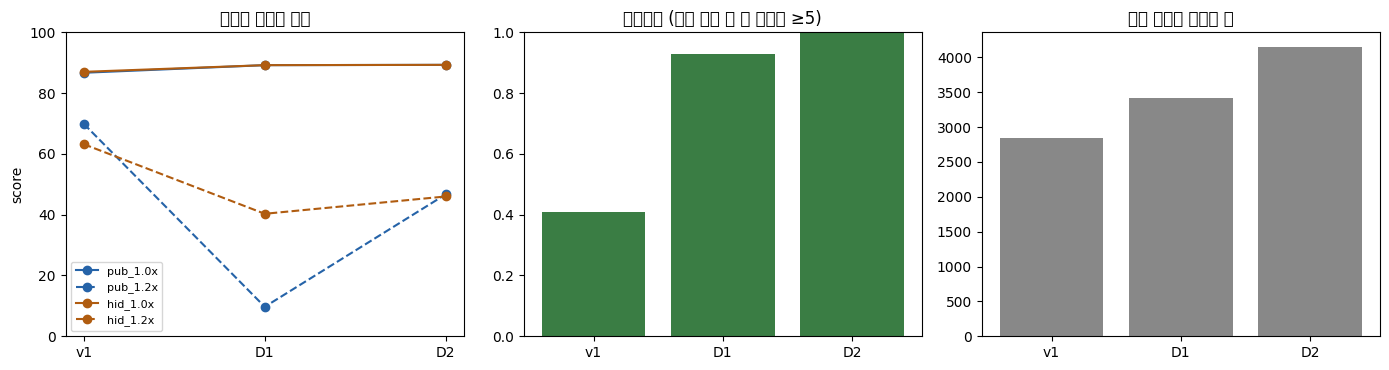

/tmp/ipykernel_3210/1639636104.py:17: UserWarning: Glyph 51665 (\N{HANGUL SYLLABLE JIB}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "coverage_after.png", dpi=120); plt.show()
/tmp/ipykernel_3210/1639636104.py:17: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "coverage_after.png", dpi=120); plt.show()
/tmp/ipykernel_3210/1639636104.py:17: UserWarning: Glyph 45936 (\N{HANGUL SYLLABLE DE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "coverage_after.png", dpi=120); plt.show()
/tmp/ipykernel_3210/1639636104.py:17: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "coverage_after.png", dpi=120); plt.show()
/tmp/ipykernel_3210/1639636104.py:17: UserWarning: Glyph 53552 (\N{HANGUL SYLLABLE TEO}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SA

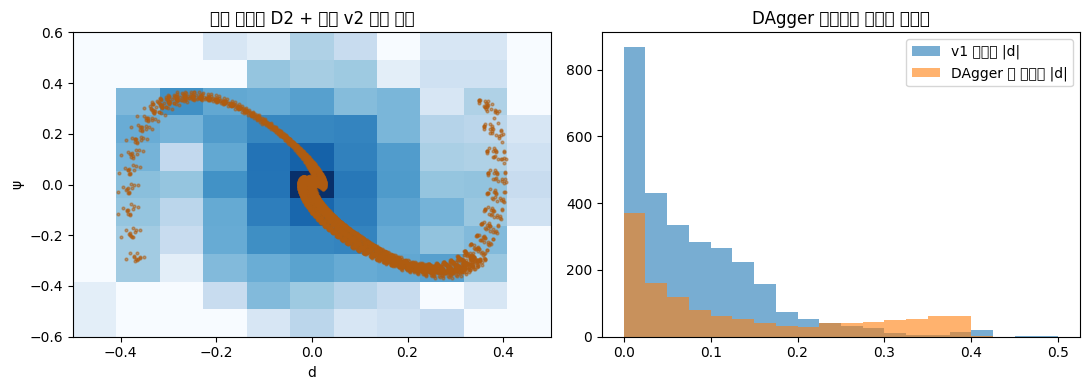

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
x = np.arange(len(df))
for col, c, ls in [("pub_1.0x", "#2563A8", "-"), ("pub_1.2x", "#2563A8", "--"), ("hid_1.0x", "#B05C10", "-"), ("hid_1.2x", "#B05C10", "--")]:
    ax[0].plot(x, df[col], "o" + ls, color=c, label=col)
ax[0].set_xticks(x); ax[0].set_xticklabels(df["round"]); ax[0].set_ylim(0, 100); ax[0].set_ylabel("score"); ax[0].legend(fontsize=8); ax[0].set_title("회전별 폐루프 점수")
ax[1].bar(x, df["coverage"], color="#3A7D44"); ax[1].set_xticks(x); ax[1].set_xticklabels(df["round"]); ax[1].set_ylim(0, 1); ax[1].set_title("커버리지 (정책 방문 칸 중 데이터 ≥5)")
ax[2].bar(x, df["frames"], color="#888"); ax[2].set_xticks(x); ax[2].set_xticklabels(df["round"]); ax[2].set_title("집계 데이터 프레임 수")
plt.tight_layout(); plt.savefig(SAVE_DIR / "dagger_curves.png", dpi=120); plt.show()

vis2 = visited_states(tt.TorchPolicy(model), PUBLIC, NORMAL)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (h, v, ttl) in zip(ax, [(state_hist(D["states"]), vis2, f"집계 데이터 D{ROUNDS} + 정책 v2 방문 상태")]):
    a.imshow(np.log1p(h).T, origin="lower", extent=[-0.5, 0.5, -0.6, 0.6], aspect="auto", cmap="Blues")
    a.scatter(v[:, 0], v[:, 1], s=4, c="#B05C10", alpha=.5); a.set_title(ttl); a.set_xlabel("d"); a.set_ylabel("ψ")
ax[1].hist(np.abs(D["states"][:N0, 0]), bins=20, range=(0, 0.5), alpha=.6, label="v1 데이터 |d|")
ax[1].hist(np.abs(D["states"][N0:, 0]), bins=20, range=(0, 0.5), alpha=.6, label="DAgger 로 추가된 |d|"); ax[1].legend(); ax[1].set_title("DAgger 데이터는 어디를 채웠나")
plt.tight_layout(); plt.savefig(SAVE_DIR / "coverage_after.png", dpi=120); plt.show()

## 5. (선택) β 혼합 수집 — 데이터 분포가 어떻게 달라지나
β=0 (정책만 운전) 과 β=0.5 (반은 전문가) 로 같은 트랙에서 400 프레임을 모아 `|d|` 분포를 비교합니다. 학습은 하지 않습니다 (10초).

In [7]:
pol_now = tt.TorchPolicy(model)
new0 = tt.dagger_collect(pol_now, tt.Track.preset("C"), 400, seed=7, disturb=NORMAL)
new5 = tt.dagger_collect(MixedPolicy(pol_now, tt.ExpertPolicy(), 0.5, seed=7), tt.Track.preset("C"), 400, seed=7, disturb=NORMAL)
for name, ds in [("β=0.0 (정책만)", new0), ("β=0.5 (반은 전문가)", new5)]:
    d_ = np.abs(ds["states"][:, 0])
    print(f"{name:18s}: mean|d| {d_.mean():.3f} | |d|>0.3 비율 {np.mean(d_ > 0.3):.2f} | run 수 {len(np.unique(ds['run_id']))} (이탈 리셋 횟수+1)")
print("해석: β 가 크면 궤적이 도로 위에 머물러 극단 상태는 줄고 리셋도 줄어든다. 정책이 형편없을 때 β 를 쓰고, 좋아지면 0 으로.")

β=0.0 (정책만)       : mean|d| 0.102 | |d|>0.3 비율 0.12 | run 수 1 (이탈 리셋 횟수+1)
β=0.5 (반은 전문가)    : mean|d| 0.099 | |d|>0.3 비율 0.11 | run 수 1 (이탈 리셋 횟수+1)
해석: β 가 크면 궤적이 도로 위에 머물러 극단 상태는 줄고 리셋도 줄어든다. 정책이 형편없을 때 β 를 쓰고, 좋아지면 0 으로.


## 6. 짝지은 비교 — v1 vs v2, 같은 시드 3개
한 번의 점수는 표본 하나입니다. 같은 외란 시드로 두 정책을 짝지어 세 번 비교합니다 (외란 1.2×, 공개 트랙).

In [8]:
pol_v1 = tt.TorchPolicy(tt.load_model(SAVE_DIR / "policy_round0.pt"))
pol_v2 = tt.TorchPolicy(model)
seeds = (0, 1, 2); t0 = time.time()
a = np.array([tt.evaluate(pol_v1, PUBLIC, seed=s, disturb=HARD)["score"] for s in seeds])
b = np.array([tt.evaluate(pol_v2, PUBLIC, seed=s, disturb=HARD)["score"] for s in seeds])
print("시드      :", seeds); print("v1 (1.2x) :", a.round(1)); print("v2 (1.2x) :", b.round(1))
diff = b - a
print(f"v2 − v1   : 평균 {diff.mean():+.1f}, 최소 {diff.min():+.1f}, 최대 {diff.max():+.1f}  ({time.time()-t0:.0f}s)")
print("세 시드 모두 + 면 확신, 부호가 섞이면 '아직 모름' → 에피소드·회전을 늘려 다시" if (diff > 0).all() or (diff < 0).all() else "부호가 섞임 → 회전을 더 돌리거나 n_episodes 를 늘려 다시 비교")

시드      : (0, 1, 2)
v1 (1.2x) : [69.9 83.  55.9]
v2 (1.2x) : [46.7 57.5 27.8]
v2 − v1   : 평균 -25.6, 최소 -28.0, 최대 -23.2  (94s)
세 시드 모두 + 면 확신, 부호가 섞이면 '아직 모름' → 에피소드·회전을 늘려 다시


## 7. 저장 — 정책 v2 · 집계 데이터 · 실험 기록
1.2× 공개 score 가 가장 높은 회전을 v2 로 고릅니다. ONNX 계약은 그대로(`image → steer`).

In [9]:
best = int(df["pub_1.2x"].idxmax())
best_model = tt.load_model(SAVE_DIR / f"policy_round{best}.pt")
onnx_path = tt.export_onnx(best_model, SAVE_DIR / "my_policy_v2.onnx"); torch.save(best_model.state_dict(), SAVE_DIR / "my_policy_v2.pt")
pol_chk = tt.OnnxPolicy(onnx_path); chk = tt.evaluate(pol_chk, PUBLIC)
print(f"v2 = round {df.loc[best,'round']} | ONNX 폐루프(1.0x) {chk['score']:.1f} | {onnx_path}")
tt.save_npz(SAVE_DIR / "my_dataset_v2.npz", D, version="v2", rounds=ROUNDS, base="v1")
json.dump(dict(rounds=log, best_round=df.loc[best, "round"], paired_v2_minus_v1=diff.tolist()), open(SAVE_DIR / "dagger_result.json", "w"), indent=1)
rec = ROOT / "experiments.csv"
pd.DataFrame(log).assign(week=7, note="DAgger, 이어서 3에폭, lr 3e-4").to_csv(rec, mode="a", header=not rec.exists(), index=False)
print("저장:", [p.name for p in SAVE_DIR.iterdir()])

v2 = round v1 | ONNX 폐루프(1.0x) 86.7 | /content/drive/MyDrive/AIApp/week07/my_policy_v2.onnx
저장: ['policy_round0.pt', 'coverage_round0.png', 'policy_round1.pt', 'policy_round2.pt', 'dagger_log.csv', 'dagger_curves.png', 'coverage_after.png', 'my_policy_v2.onnx', 'my_policy_v2.pt', 'my_dataset_v2.npz', 'dagger_result.json']


## 8. (집에서) 회전 3~5 이어서
`EXTRA_ROUNDS` 를 3 으로 바꾸고 실행하세요 (회전당 약 2분). 곡선이 평탄해지는 회전이 '내 데이터의 한계'입니다. 그 뒤엔 트랙 다양성(`tt.Track.random`)·리밸런스·증강을 손댈 차례.

In [10]:
EXTRA_ROUNDS = 0          # ← 집에서 3 으로
for r in range(ROUNDS + 1, ROUNDS + 1 + EXTRA_ROUNDS):
    t0 = time.time()
    model, D, new = dagger_round(model, D, PUBLIC + [tt.Track.random(300 + r)], n_per_track=N_PER_TRACK, seed=r, epochs=EPOCHS)
    torch.save(model.state_dict(), SAVE_DIR / f"policy_round{r}.pt")
    pol = tt.TorchPolicy(model); vis = visited_states(pol, PUBLIC, NORMAL)
    log.append(dict(round=f"D{r}", frames=len(D["steers"]), coverage=round(coverage(D["states"], vis), 2), **evaluate_all(pol), sec=round(time.time() - t0)))
    print(pd.DataFrame(log[-1:]).to_string(index=False, header=False))
if EXTRA_ROUNDS:
    df = pd.DataFrame(log); df.to_csv(SAVE_DIR / "dagger_log.csv", index=False); print(df.to_string(index=False))

## 정리 · 제출
- 오프라인은 전문가 분포 위의 점수, 폐루프는 정책 분포 위의 점수. 정책이 가는 곳에 데이터가 없으면 오차가 누적된다 (O(εT²)).
- DAgger = 정책이 운전, 전문가가 라벨, 집계, 재학습 → O(εT). 1.0× 는 상한 근처, **1.2× 에서 개선이 보인다.**
- 비교는 같은 시드로 짝지어, 결론은 반복으로.

**리더보드 v2 제출**: `week07/my_policy_v2.onnx` 를 GitHub 개인 저장소에 push + Mattermost 링크 (수요일 12:00 까지). 1.0× / 1.2× 두 열로 게시.
**다음 주 준비**: `week07/my_policy_v2.pt` 와 `my_dataset_v2.npz` — 8주차 비교 실험의 출발점.